# Figures – Global Disease Network

Figures for the report and the presentation. Run `network_builder.py` first – this notebook reads the cleaned dataset and the network files it exported.

## 0 Setup

In [2]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd

import build_network as nb

In [3]:
# Config +++
DATA_FILE = Path("./../data/processed/clean_2019.csv")
NETWORK_DIR = Path("./../data/network")

COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]  # same as viewer

COMMUNITY_NAMES = {
    1: "Cancers",
    2: "Low-mortality",
    3: "Mixed chronic",
    4: "Maternal & tropical",
    5: "Infections & digestive",
    6: "Malnutrition & diarrhoea",
    7: "Heart & injuries",
    8: "Alcohol & liver",
    9: "Vaccine-preventable & TB",
    10: "HIV & violence",
    11: "Drug use & head-neck cancer",
}

PAIRS = [  # example pairs for figure 2
    ("hiv_aids", "drowning"),
    ("alcohol_use_disorders", "cirrhosis_due_to_alcohol_use"),
    ("measles", "whooping_cough"),
    ("trachea_bronchus_lung_cancers", "chronic_obstructive_pulmonary_disease"),
]

SHORT = {  # short chart labels
    "hiv_aids": "HIV", "tuberculosis": "TB", "trachea_bronchus_lung_cancers": "lung cancer",
    "chronic_obstructive_pulmonary_disease": "COPD", "alcohol_use_disorders": "alcohol use",
    "cirrhosis_due_to_alcohol_use": "cirrhosis (alcohol)", "cirrhosis_due_to_hepatitis_b": "cirrhosis (hep B)",
    "liver_cancer_secondary_to_hepatitis_b": "liver cancer (hep B)", "diabetes_mellitus": "diabetes",
    "chronic_kidney_disease_due_to_diabetes": "CKD (diabetes)", "other_chronic_kidney_disease": "other CKD",
    "ischaemic_heart_disease": "heart disease", "ischaemic_stroke": "stroke", "cervix_uteri_cancer": "cervical cancer",
    "maternal_conditions": "maternal", "birth_asphyxia_and_birth_trauma": "birth asphyxia",
    "neonatal_sepsis_and_infections": "neonatal sepsis", "diarrhoeal_diseases": "diarrhoea",
    "protein_energy_malnutrition": "malnutrition", "collective_violence_and_legal_intervention": "conflict",
    "dtp3_coverage": "DTP3", "measles_coverage": "measles vacc.", "skilled_birth_attendance": "birth attendance",
    "basic_water_access": "water", "basic_sanitation_access": "sanitation", "avail_dialysis": "dialysis",
    "avail_insulin": "insulin", "avail_thrombolysis": "thrombolysis", "avail_coronary_bypass_stent": "stents",
    "avail_cervical_cytology": "cervical screening", "avail_bronchodilators": "bronchodilators",
    "tb_incidence": "TB incidence", "hiv_prevalence_15_49": "HIV prevalence", "hepb_prevalence": "hep B",
    "alcohol_per_capita": "alcohol", "tobacco_prevalence": "tobacco", "pm25_exposure": "PM2.5",
    "raised_glucose_prevalence": "glucose", "obesity_prevalence": "obesity", "stunting_prevalence": "stunting",
    "battle_deaths_per100k": "battle deaths",
}
# Config ---

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e6e6", "axes.axisbelow": True, "legend.frameon": False})


def short(name):
    """Short chart label for a cause or indicator.

    Parameters
    name: str, e.g. "death_asdr_trachea_bronchus_lung_cancers" or "trachea bronchus lung cancers"

    Returns
    str, e.g. "lung cancer"
    """
    key = name.replace("death_asdr_", "").replace(" ", "_")
    return SHORT.get(key, key.replace("_", " "))

### Load data
- `raw`: Spearman correlation between all causes
- `adjusted`: the same with GDP removed (co-occurrence)
- `direct`: graphical lasso partial correlations (direct links), takes ~20 s
- `nodes`, `edges`, `expected`: output of `network_builder.py`

In [4]:
data = pd.read_csv(DATA_FILE)
causes = [c for c in data.columns if c.startswith("death_asdr_")]
residuals = nb.remove_control(data[causes], data[nb.CONTROL])

raw = data[causes].corr(method="spearman")
adjusted = residuals.corr()
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    direct, alpha = nb.direct_links(residuals)

nodes = pd.read_csv(NETWORK_DIR / "nodes_glasso.csv")
edges = {m: pd.read_csv(NETWORK_DIR / f"edges_{m}.csv") for m in ["correlation", "glasso"]}
expected = pd.read_csv(NETWORK_DIR / "expected_links.csv")
cause_nodes = nodes[nodes["type"] == "cause"].set_index("id")
print(f"{len(data)} countries, {len(causes)} causes, alpha = {alpha:.3f}")

182 countries, 139 causes, alpha = 0.190


## 1 Wealth effect

Correlation between every pair of causes (9,591 pairs), before and after removing GDP. "Strong" = |ρ| ≥ 0.5.

Raw: rich and poor countries have different death profiles, so most diseases of poverty correlate with each other. After removing GDP the distribution collapses around 0 – strong pairs drop from 27% to 2%.

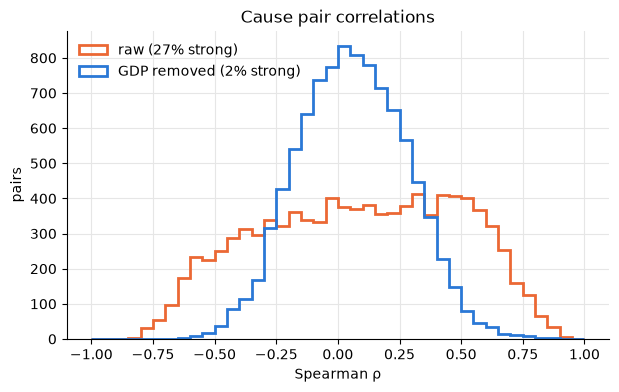

In [5]:
upper = np.triu_indices(len(causes), k=1)   # every pair once

fig, ax = plt.subplots(figsize=(7, 4))
for matrix, color, name in [(raw, COLORS[1], "raw"), (adjusted, COLORS[0], "GDP removed")]:
    values = matrix.values[upper]
    strong = np.mean(np.abs(values) >= 0.5)
    ax.hist(values, bins=40, range=(-1, 1), histtype="step", linewidth=2, color=color, label=f"{name} ({strong:.0%} strong)")
ax.set_xlabel("Spearman ρ")
ax.set_ylabel("pairs")
ax.set_title("Cause pair correlations")
ax.legend()
plt.show()

## 2 Example pairs

Link strength in three steps: raw → GDP removed → direct link (given all other causes).

- **HIV – drowning:** both high in southern Africa, no direct link.
- **Alcohol use – cirrhosis (alcohol):** survives every step.
- **Measles – whooping cough:** explained by the other vaccine-preventable diseases.
- **Lung cancer – COPD:** shared cause (smoking) but weak – the graphical lasso can miss real links.

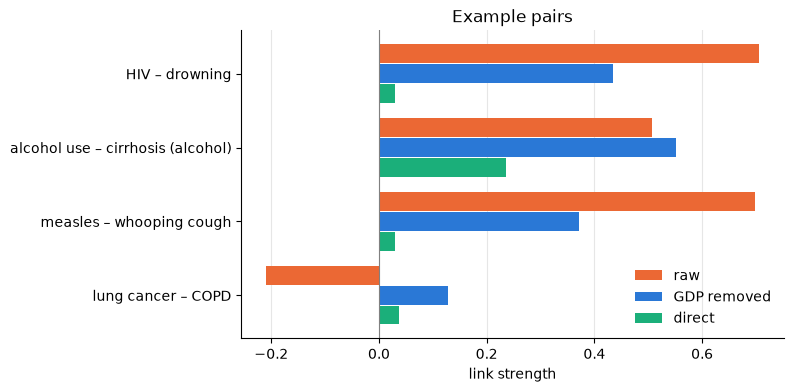

In [6]:
y = np.arange(len(PAIRS))
steps = [(raw, COLORS[1], "raw"), (adjusted, COLORS[0], "GDP removed"), (direct, COLORS[2], "direct")]

fig, ax = plt.subplots(figsize=(7, 4))
for k, (matrix, color, name) in enumerate(steps):
    values = [matrix.loc["death_asdr_" + a, "death_asdr_" + b] for a, b in PAIRS]
    ax.barh(y + (k - 1) * 0.27, values, height=0.25, color=color, label=name)
ax.axvline(0, color="grey", linewidth=0.8)
ax.set_yticks(y, [f"{short(a)} – {short(b)}" for a, b in PAIRS])
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_xlabel("link strength")
ax.set_title("Example pairs")
ax.legend()
plt.show()

## 3 Direct-link network

Colour = community, size = number of links. Communities 9–11 are rings (only 8 colour-blind-safe colours). Links inside a community pull harder in the layout so the communities are visible; positions have no meaning otherwise.

In [7]:
# layout (used again in figure 6)
community = cause_nodes["community"]
G = nx.Graph()
G.add_nodes_from(cause_nodes.index)
links = edges["glasso"][edges["glasso"]["type"] == "cause-cause"]
for a, b, w in links[["source", "target", "weight"]].itertuples(index=False):
    G.add_edge(a, b, weight=w, pull=w * (15 if community[a] == community[b] else 1))
pos = nx.spring_layout(G, weight="pull", seed=42, k=0.3, iterations=500)

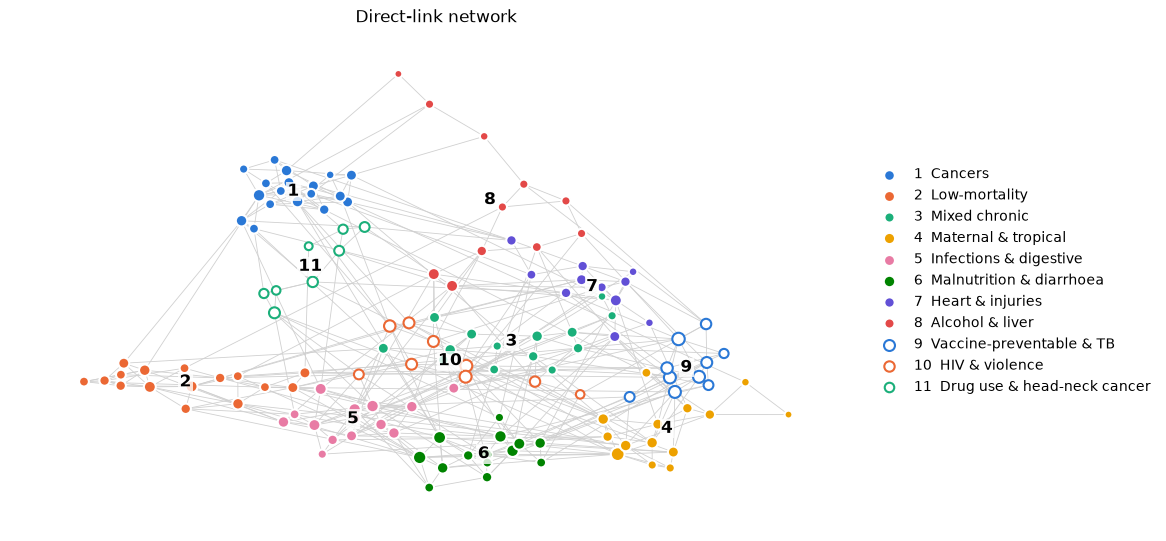

In [8]:
fig, ax = plt.subplots(figsize=(11, 6.5))
nx.draw_networkx_edges(G, pos, ax=ax, edge_color="#d0d0d0", width=0.6)
for c, group in cause_nodes.groupby("community"):
    color = COLORS[(c - 1) % len(COLORS)]
    ring = c > len(COLORS)
    ax.scatter([pos[n][0] for n in group.index], [pos[n][1] for n in group.index], s=20 + 6 * group["degree"],
               c="white" if ring else color, edgecolors=color if ring else "white", linewidths=1.5, zorder=3,
               label=f"{c}  {COMMUNITY_NAMES[c]}")
    x, y = np.mean([pos[n] for n in group.index], axis=0)
    ax.text(x, y, c, fontsize=12, fontweight="bold", ha="center", va="center", zorder=4,
            bbox=dict(facecolor="white", edgecolor="none", alpha=0.8, pad=1))
ax.set_axis_off()
ax.set_title("Direct-link network")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.show()

## 4 Community stability

Countries resampled 200 times, network and communities rebuilt each time. Bar = how often the causes of a community stay together. Only cancers are very stable; three more hold in about half the samples.

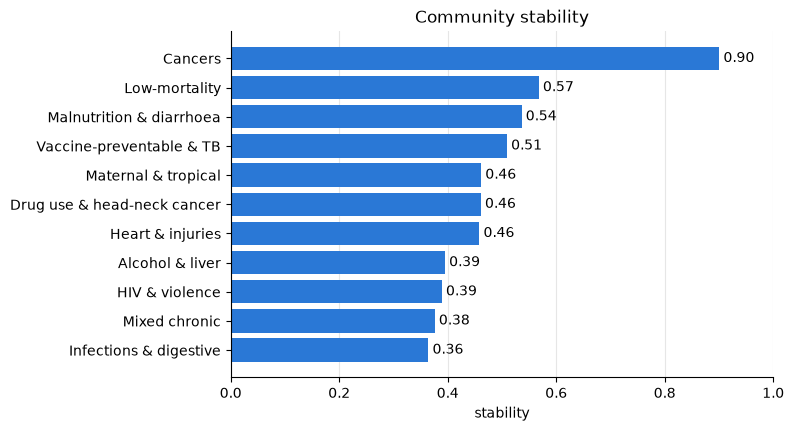

In [9]:
stability = cause_nodes.groupby("community")["stability"].mean().sort_values()

fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.barh([COMMUNITY_NAMES[c] for c in stability.index], stability, color=COLORS[0])
ax.bar_label(bars, fmt="%.2f", padding=3)
ax.set_xlim(0, 1)
ax.grid(axis="y", visible=False)
ax.set_xlabel("stability")
ax.set_title("Community stability")
plt.show()

## 5 Expected indicator links

29 indicator → cause links expected from medical knowledge. Dot = Spearman ρ with GDP removed, dashed = network threshold (±0.35).

23 of 29 have the expected sign, 11 pass the threshold. Risk factors link strongly (TB, HIV, tobacco, alcohol), coverage moderately (vaccination, sanitation), treatment availability not at all (dialysis, insulin, stents).

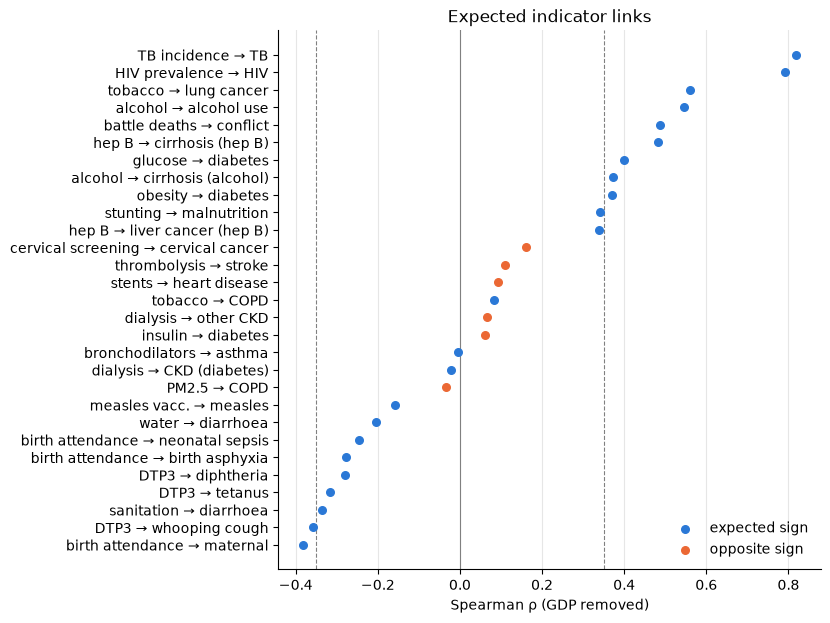

In [10]:
table = expected.sort_values("rho")
labels = [f"{short(i)} → {short(c)}" for i, c in zip(table["indicator"], table["cause"])]
y = np.arange(len(table))

fig, ax = plt.subplots(figsize=(7, 7))
for right, color, name in [(True, COLORS[0], "expected sign"), (False, COLORS[1], "opposite sign")]:
    part = (table["right_direction"] == right).values
    ax.scatter(table["rho"][part], y[part], s=30, color=color, label=name, zorder=3)
for x in (-nb.INDICATOR_THRESHOLD, nb.INDICATOR_THRESHOLD):
    ax.axvline(x, color="grey", linewidth=0.8, linestyle="--")
ax.axvline(0, color="grey", linewidth=0.8)
ax.set_yticks(y, labels)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Spearman ρ (GDP removed)")
ax.set_title("Expected indicator links")
ax.legend(loc="lower right")
plt.show()

## 6 Co-occurrence vs direct links

Same node positions as figure 3, colour = WHO cause group. Grey = link in both networks, red = only in this one.

The co-occurrence network has about twice as many links, most of them in the large poverty block. Most direct links also exist in the co-occurrence network.

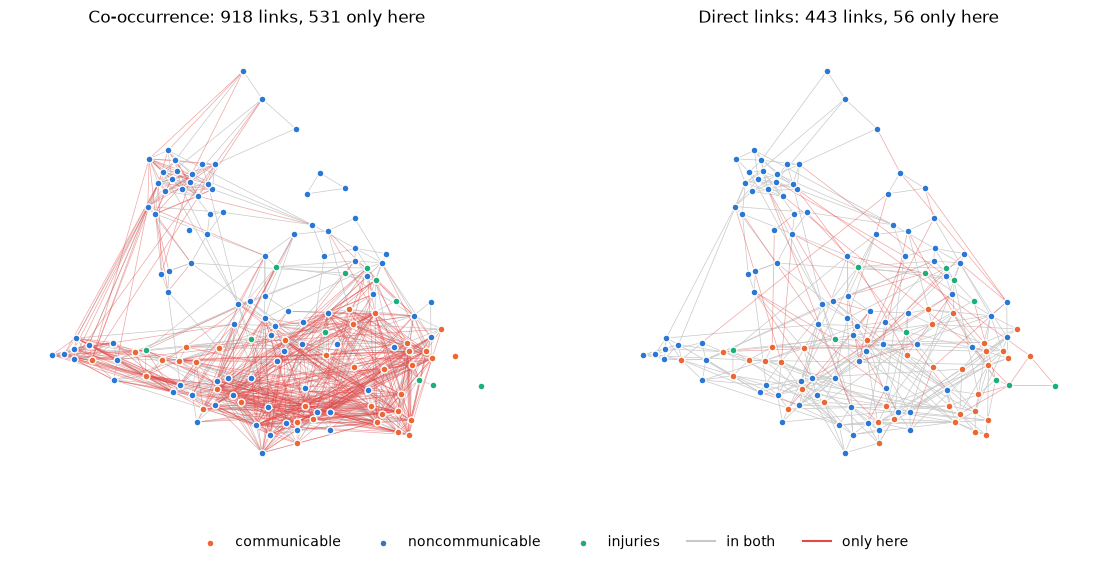

In [11]:
link_sets = {m: {frozenset(e) for e in df[df["type"] == "cause-cause"][["source", "target"]].itertuples(index=False)}
             for m, df in edges.items()}
category_colors = {"communicable": COLORS[1], "noncommunicable": COLORS[0], "injuries": COLORS[2]}

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, m, other, title in [(axes[0], "correlation", "glasso", "Co-occurrence"), (axes[1], "glasso", "correlation", "Direct links")]:
    both = [tuple(e) for e in link_sets[m] & link_sets[other]]
    only = [tuple(e) for e in link_sets[m] - link_sets[other]]
    nx.draw_networkx_edges(G, pos, edgelist=both, ax=ax, edge_color="#c8c8c8", width=0.5)
    nx.draw_networkx_edges(G, pos, edgelist=only, ax=ax, edge_color=COLORS[7], width=0.5, alpha=0.5)
    for category, color in category_colors.items():
        members = cause_nodes.index[cause_nodes["category"] == category]
        ax.scatter([pos[n][0] for n in members], [pos[n][1] for n in members], s=25, c=color,
                   edgecolors="white", zorder=3, label=category)
    ax.set_title(f"{title}: {len(link_sets[m])} links, {len(only)} only here")
    ax.set_axis_off()
axes[0].plot([], [], color="#c8c8c8", label="in both")
axes[0].plot([], [], color=COLORS[7], label="only here")
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=5)
plt.show()